# Online Shopping Purchase Prediction

**Module:** KH6001CMD Machine Learning  
**Project:** Predicting whether an online shopping session results in a purchase

## Problem statement

This project will investigate if information stored about customer online shopping habits can help predict if a visitor completes a purchase.

The target column is 'Revenue'. It tells us whether a session resulted in a purchase or not (T/F).

## Import libraries and make directories for data

In [30]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Path("data/raw").mkdir(parents=True, exist_ok=True)
Path("data/processed").mkdir(parents=True, exist_ok=True)

## Loading the Dataset

In [31]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv"
file_path = Path("data/raw/online_shoppers_intention.csv")

if file_path.exists():
    df = pd.read_csv(file_path)
else:
    df = pd.read_csv(url)
    df.to_csv(file_path, index=False)

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## Check data types, missing values, duplicates, etc.

In [32]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-missing values:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))

print("Duplicate rows:", df.duplicated().sum())

Column names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Data types and non-missing values:
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues     

,Missing values
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


Duplicate rows: 125


## Checking class imbalance for 'Revenue'

Purchase percentages:


,Percentage
Revenue,
False,84.53
True,15.47


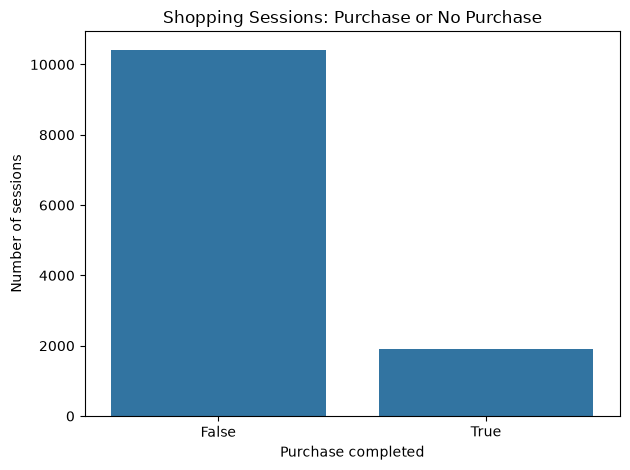

In [33]:
print("Purchase percentages:")
display((df["Revenue"].value_counts(normalize=True) * 100).round(2).to_frame("Percentage"))

sns.countplot(data=df, x="Revenue")
plt.title("Shopping Sessions: Purchase or No Purchase")
plt.xlabel("Purchase completed")
plt.ylabel("Number of sessions")
plt.tight_layout()
plt.show()

## Create the personalized dataset

In [34]:
from sklearn.model_selection import train_test_split

personalised_df, unused_data = train_test_split(df, test_size=0.20, random_state=202300408, stratify=df["Revenue"])
personalised_df = personalised_df.reset_index(drop=True)
personalised_df.to_csv("data/processed/personalized_online_shoppers.csv", index=False)

print("Original rows:", len(df))
print("Personalized rows:", len(personalised_df))
print("Student ID seed: 202300408")

display(personalised_df["Revenue"].value_counts().to_frame("Purchase counts"))

Original rows: 12330
Personalized rows: 9864
Student ID seed: 202300408


,Purchase counts
Revenue,
False,8338
True,1526


## Check personalized dataset and add features

In [35]:
display(personalised_df.describe(include="all").T)

print("Missing values:")
display(personalised_df.isnull().sum().to_frame("Missing values"))

personalised_df.drop_duplicates(inplace=True)
print("Duplicate rows left:", personalised_df.duplicated().sum())

personalised_df['Total_Pages'] = (personalised_df['Administrative'] + personalised_df['Informational'] + personalised_df['ProductRelated'])
personalised_df['Total_Duration'] = (personalised_df['Administrative_Duration'] + personalised_df['Informational_Duration'] +personalised_df['ProductRelated_Duration'])

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,9864.0,NaN,NaN,NaN,2.300791,3.291702,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,9864.0,NaN,NaN,NaN,80.545453,174.807205,0.0,0.0,8.0,91.5,2657.318056
Informational,9864.0,NaN,NaN,NaN,0.505373,1.250275,0.0,0.0,0.0,0.0,16.0
Informational_Duration,9864.0,NaN,NaN,NaN,33.42591,133.950299,0.0,0.0,0.0,0.0,2195.3
ProductRelated,9864.0,NaN,NaN,NaN,31.957725,45.003114,0.0,7.0,18.0,38.0,686.0
ProductRelated_Duration,9864.0,NaN,NaN,NaN,1198.441567,1836.121193,0.0,183.0,597.941527,1460.333753,29970.46597
BounceRates,9864.0,NaN,NaN,NaN,0.022377,0.048711,0.0,0.0,0.0032,0.016667,0.2
ExitRates,9864.0,NaN,NaN,NaN,0.043187,0.04881,0.0,0.014257,0.025288,0.05,0.2
PageValues,9864.0,NaN,NaN,NaN,5.835333,18.445454,0.0,0.0,0.0,0.0,361.763742
SpecialDay,9864.0,NaN,NaN,NaN,0.061152,0.199277,0.0,0.0,0.0,0.0,1.0


Missing values:


,Missing values
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


Duplicate rows left: 0


## Numerical feature distributions and correlations

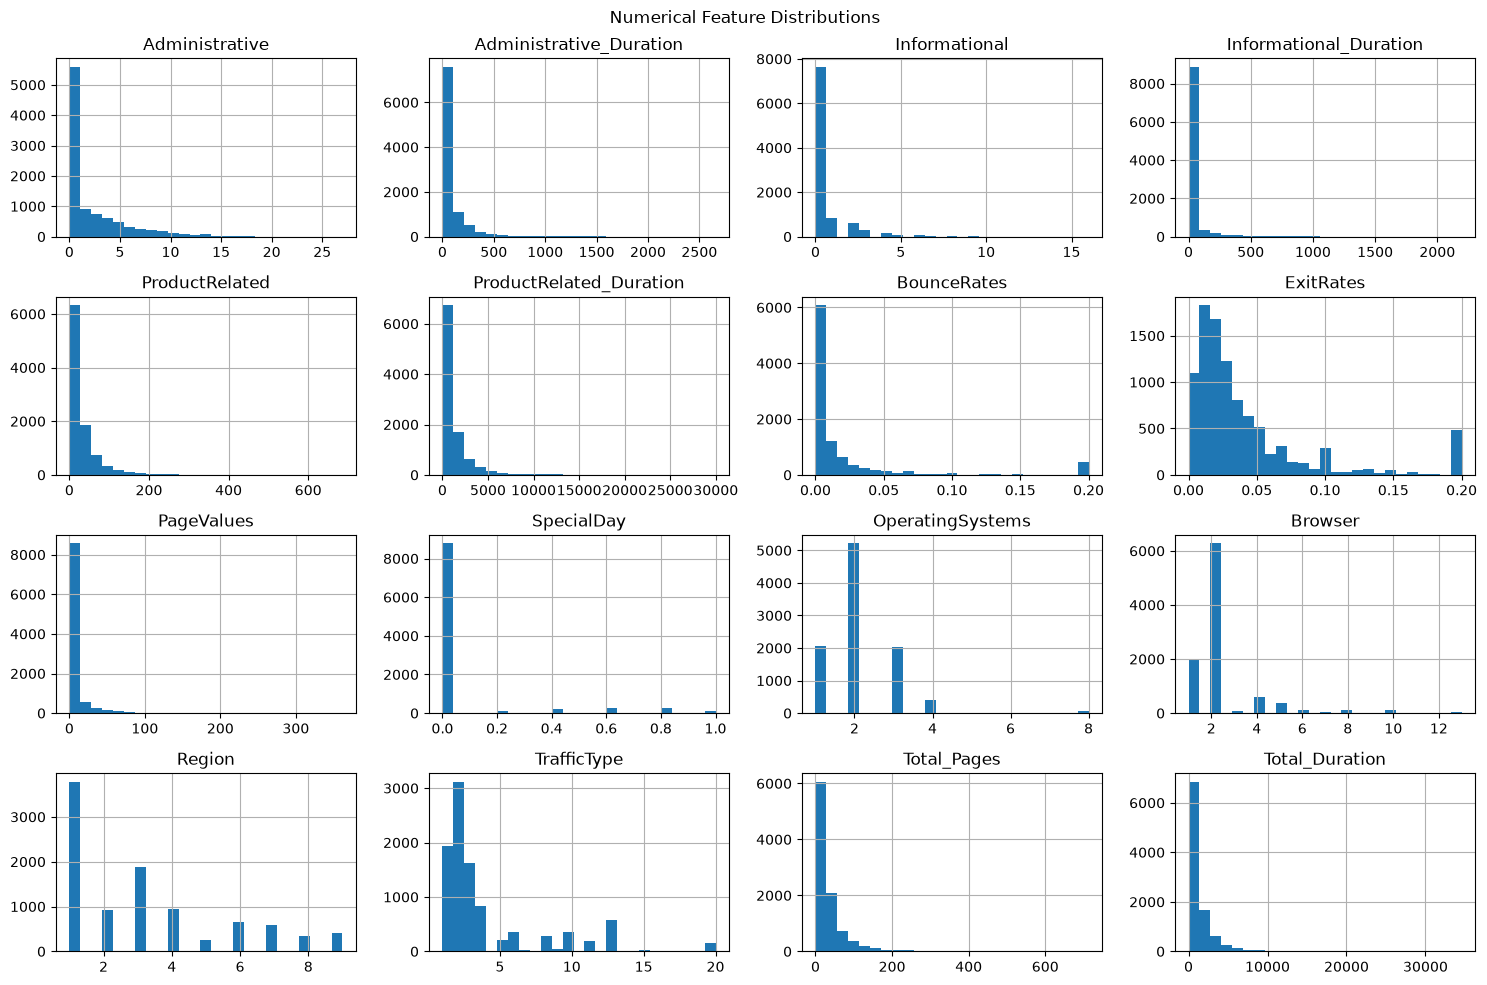

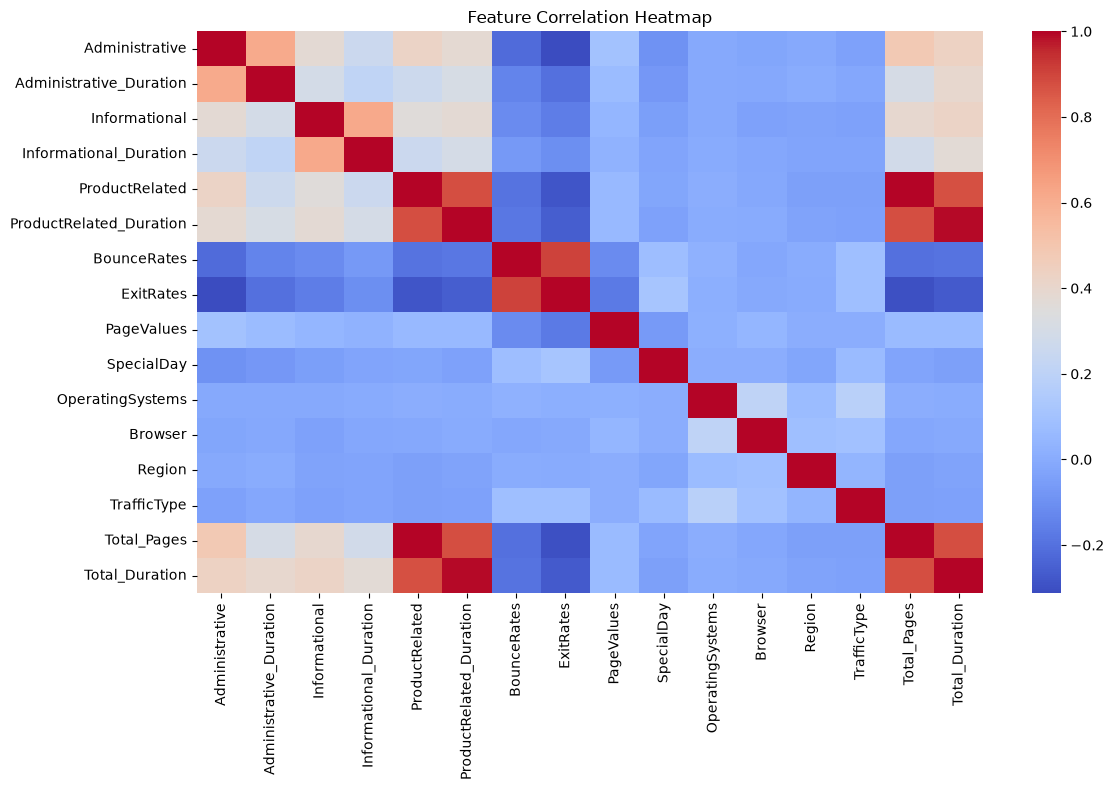

In [36]:
personalised_df.select_dtypes(include="number").hist(
    figsize=(15, 10),
    bins=25
)
plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
numeric_data = personalised_df.select_dtypes(include="number")
sns.heatmap(numeric_data.corr(), annot=False, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

## Removing Outliers

In [37]:
skewed_cols = ['ProductRelated_Duration', 'Administrative_Duration', 'Informational_Duration', 'PageValues']

for col in skewed_cols:
    Q1 = personalised_df[col].quantile(0.25)
    Q3 = personalised_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    personalised_df[col] = personalised_df[col].clip(lower_bound, upper_bound)

## Separate the input features and target and create test/train split

In [38]:
X = personalised_df.drop(columns=["Revenue"])
y = personalised_df["Revenue"].astype(int)

#random state is set to student ID
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20, random_state=202300408, stratify=y)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 7818
Testing rows: 1955


## Preprocessing for numerical and categorical data

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

number_columns = X_train.select_dtypes(include="number").columns.tolist()
category_columns = X_train.select_dtypes(exclude="number").columns.tolist()

numerical_pipeline = Pipeline([("fill_missing", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
categorical_pipeline = Pipeline([("fill_missing", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore"))])

prepare_data = ColumnTransformer([("numbers", numerical_pipeline, number_columns), ("categories", categorical_pipeline, category_columns)])

X_train_fitted = prepare_data.fit_transform(X_train)
X_test_fitted = prepare_data.transform(X_test)

print("Prepared training data:", X_train_fitted.shape)
print("Prepared test data:", X_test_fitted.shape)

personalised_df.to_csv("data/processed/personalized_online_shoppers.csv", index=False)

Prepared training data: (7818, 31)
Prepared test data: (1955, 31)
